# Results

In [2]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent
sys.path.append(str(PROJECT_ROOT))

In [3]:
OUTPUTS = PROJECT_ROOT / "outputs"
OUTPUTS.mkdir(parents=True, exist_ok=True)

In [4]:
from src.experiments.artifacts import ReconstructedStore

store = ReconstructedStore(OUTPUTS / "reconstructed")

In [5]:
from src.figures_cfg import (apply_theme, plot_reconstruction, MECHANISM_COLORS,
                         MECHANISM_ORDER, FORECASTER_ORDER)
apply_theme()

In [6]:
import pandas as pd
import numpy as np

In [7]:
bv_df = pd.read_parquet(OUTPUTS / "bias_variance.parquet")

---

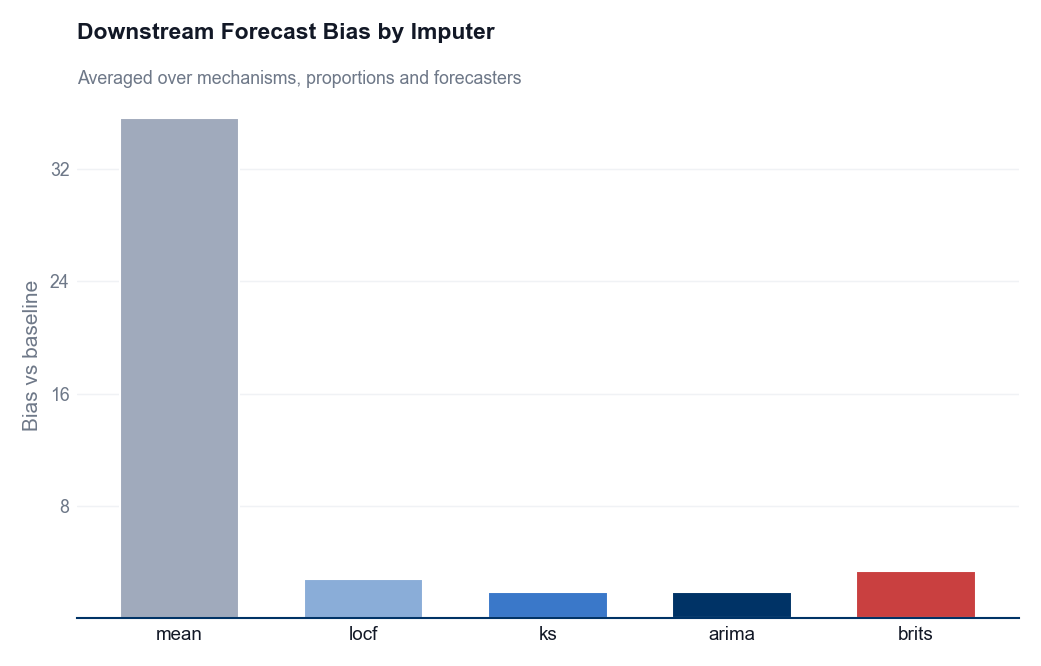

In [7]:
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
from src.figures_cfg import (apply_theme, IMPUTER_COLORS, IMPUTER_ORDER,
                         PRIMARY, MUTED, INK, LIGHT, WHITE)
apply_theme()

agg = bv_df.groupby("imputer")["bias_vs_baseline"].mean().reindex(IMPUTER_ORDER)

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.bar(range(len(agg)), agg.values,
       color=[IMPUTER_COLORS[i] for i in agg.index], width=0.65)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_visible(False)
ax.spines["bottom"].set_color(PRIMARY)
ax.spines["bottom"].set_linewidth(1.0)
ax.grid(axis="y", color=LIGHT, linewidth=0.7)
ax.set_facecolor(WHITE)
ax.set_xticks(range(len(agg)))
ax.set_xticklabels(agg.index, fontsize=9, color=INK)
ax.tick_params(axis="y", labelsize=8.5, colors=MUTED)
ax.tick_params(axis="x", length=0)
ax.yaxis.set_major_locator(ticker.MaxNLocator(nbins=5, prune="both"))

ax.set_ylabel("Bias vs baseline", color=MUTED, fontsize=10)
ax.set_title("Downstream Forecast Bias by Imputer",
             color=INK, fontweight="bold", fontsize=11, loc="left", pad=26)
ax.text(0, 1.01, "Averaged over mechanisms, proportions and forecasters",
        transform=ax.transAxes, color=MUTED, fontsize=8.5, va="bottom")

fig.tight_layout()
fig.savefig(OUTPUTS / "figures/forecasting/bias_by_imputer.png")
plt.show()

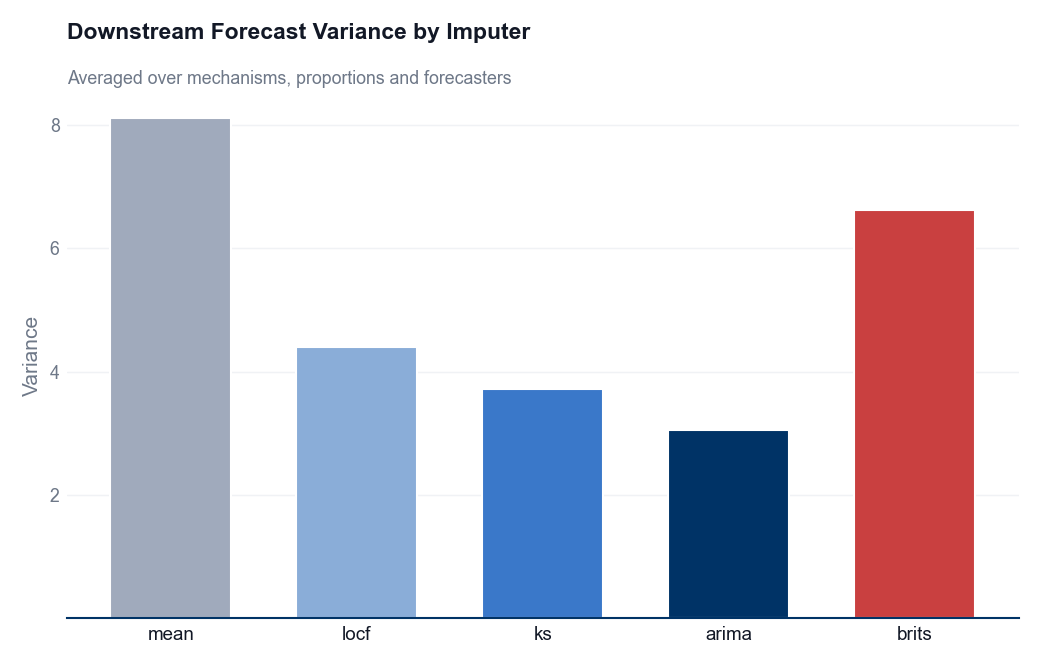

In [9]:
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
from src.figures_cfg import (apply_theme, IMPUTER_COLORS, IMPUTER_ORDER,
                         PRIMARY, MUTED, INK, LIGHT, WHITE)
apply_theme()

agg = bv_df.groupby("imputer")["variance"].mean().reindex(IMPUTER_ORDER)

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.bar(range(len(agg)), agg.values,
       color=[IMPUTER_COLORS[i] for i in agg.index], width=0.65)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_visible(False)
ax.spines["bottom"].set_color(PRIMARY)
ax.spines["bottom"].set_linewidth(1.0)
ax.grid(axis="y", color=LIGHT, linewidth=0.7)
ax.set_facecolor(WHITE)
ax.set_xticks(range(len(agg)))
ax.set_xticklabels(agg.index, fontsize=9, color=INK)
ax.tick_params(axis="y", labelsize=8.5, colors=MUTED)
ax.tick_params(axis="x", length=0)
ax.yaxis.set_major_locator(ticker.MaxNLocator(nbins=5, prune="both"))

ax.set_ylabel("Variance", color=MUTED, fontsize=10)
ax.set_title("Downstream Forecast Variance by Imputer",
             color=INK, fontweight="bold", fontsize=11, loc="left", pad=26)
ax.text(0, 1.01, "Averaged over mechanisms, proportions and forecasters",
        transform=ax.transAxes, color=MUTED, fontsize=8.5, va="bottom")

fig.tight_layout()
fig.savefig(OUTPUTS / "figures/forecasting/variance_by_imputer.png")
plt.show()

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
from src.figures_cfg import (apply_theme, IMPUTER_COLORS, IMPUTER_ORDER,
                         PRIMARY, MUTED, INK, LIGHT, WHITE)
apply_theme()

agg = bv_df.groupby("imputer")["bias_vs_baseline"].mean().reindex(IMPUTER_ORDER)

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.bar(range(len(agg)), agg.values,
       color=[IMPUTER_COLORS[i] for i in agg.index], width=0.65)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_visible(False)
ax.spines["bottom"].set_color(PRIMARY)
ax.spines["bottom"].set_linewidth(1.0)
ax.grid(axis="y", color=LIGHT, linewidth=0.7)
ax.set_facecolor(WHITE)
ax.set_xticks(range(len(agg)))
ax.set_xticklabels(agg.index, fontsize=9, color=INK)
ax.tick_params(axis="y", labelsize=8.5, colors=MUTED)
ax.tick_params(axis="x", length=0)
ax.yaxis.set_major_locator(ticker.MaxNLocator(nbins=5, prune="both"))

ax.set_ylabel("Bias vs baseline", color=MUTED, fontsize=10)
ax.set_title("Downstream Forecast Bias by Imputer",
             color=INK, fontweight="bold", fontsize=11, loc="left", pad=26)
ax.text(0, 1.01, "Averaged over mechanisms, proportions and forecasters",
        transform=ax.transAxes, color=MUTED, fontsize=8.5, va="bottom")

fig.tight_layout()
fig.savefig(OUTPUTS / "figures/forecasting/bias_by_imputer.png")
plt.show()

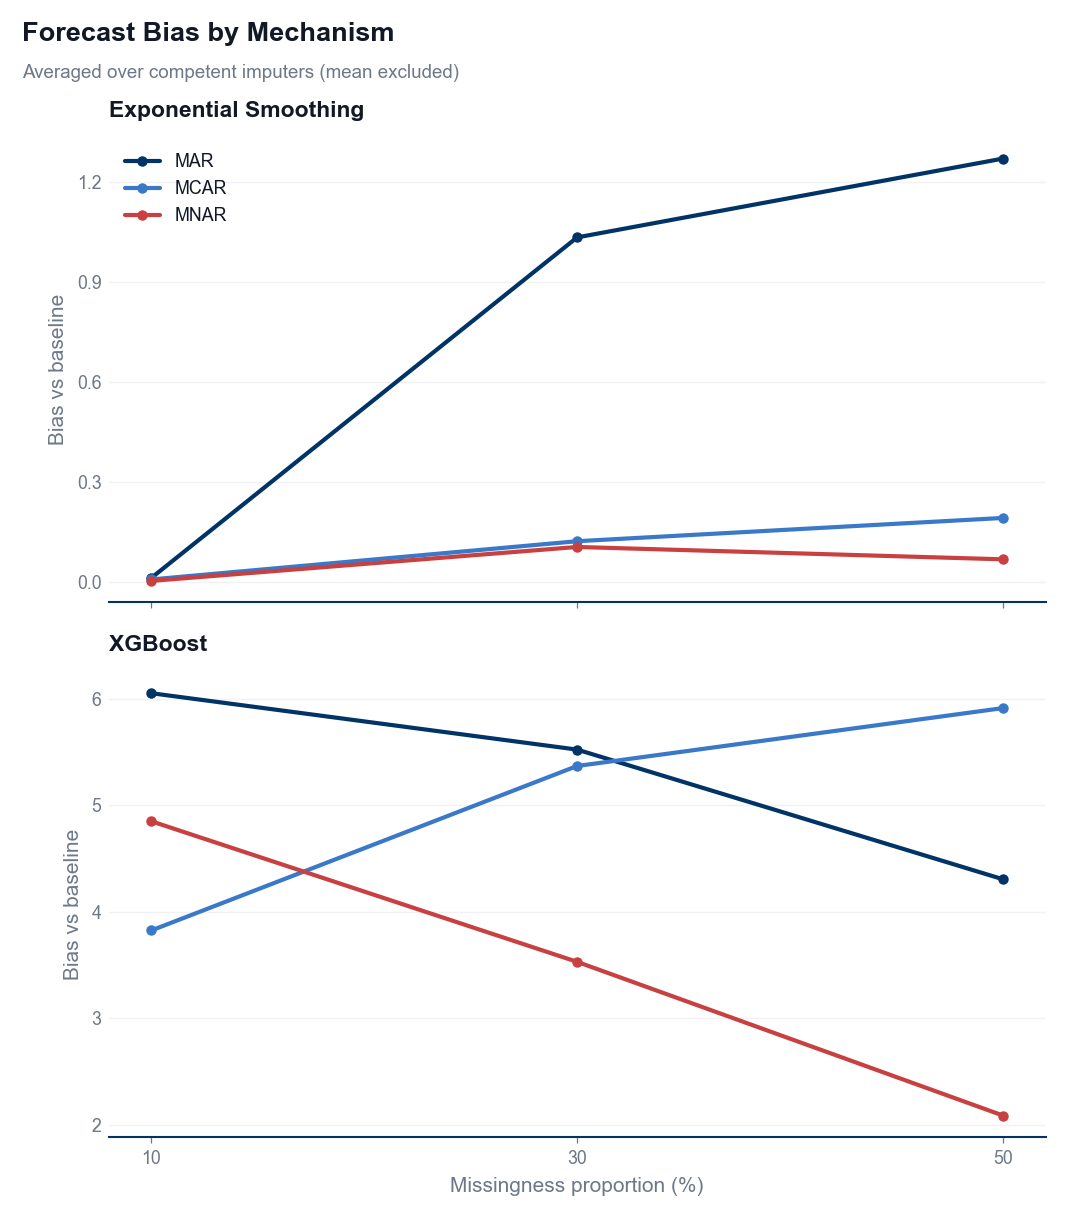

In [8]:
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
from src.figures_cfg import (apply_theme, MECHANISM_ORDER, MECHANISM_COLORS, PRIMARY, MUTED, INK, LIGHT, WHITE)
apply_theme()

forecasters = ["exp_smoothing", "xgboost"]
titles = {"exp_smoothing": "Exponential Smoothing", "xgboost": "XGBoost"}

agg = (bv_df[bv_df["imputer"] != "mean"]
       .groupby(["forecaster", "proportion", "mechanism"])["bias_vs_baseline"]
       .mean().reset_index())

fig, axes = plt.subplots(2, 1, figsize=(7, 8), sharex=True)   # stacked, share x
for ax, fc in zip(axes, forecasters):
    sub = agg[agg["forecaster"] == fc]
    for mech in MECHANISM_ORDER:
        g = sub[sub["mechanism"] == mech].sort_values("proportion")
        ax.plot(g["proportion"], g["bias_vs_baseline"], marker="o", markersize=4,
                color=MECHANISM_COLORS[mech], label=mech.upper())
    ax.spines["top"].set_visible(False); ax.spines["right"].set_visible(False)
    ax.spines["left"].set_visible(False)
    ax.spines["bottom"].set_color(PRIMARY); ax.spines["bottom"].set_linewidth(1.0)
    ax.grid(axis="y", color=LIGHT, linewidth=0.7); ax.set_facecolor(WHITE)
    ax.tick_params(axis="y", labelsize=8.5, colors=MUTED)
    ax.yaxis.set_major_locator(ticker.MaxNLocator(nbins=5, prune="both"))
    ax.set_ylabel("Bias vs baseline", color=MUTED, fontsize=10)
    ax.set_title(titles[fc], color=INK, fontweight="bold", fontsize=11, loc="left", pad=10)

axes[-1].set_xticks([10, 30, 50])
axes[-1].tick_params(axis="x", labelsize=8.5, colors=MUTED)
axes[-1].set_xlabel("Missingness proportion (%)", color=MUTED, fontsize=10)
axes[0].legend(frameon=False, fontsize=8.5, labelcolor=INK, loc="upper left")

fig.suptitle("Forecast Bias by Mechanism", x=0.0, ha="left",
             fontsize=13, fontweight="bold", color=INK, y=1.0)
fig.text(0.0, 0.965, "Averaged over competent imputers (mean excluded)",
         ha="left", fontsize=9, color=MUTED, va="top")
fig.tight_layout()
fig.savefig(OUTPUTS / "figures/forecasting/bias_by_mechanism.png")
plt.show()

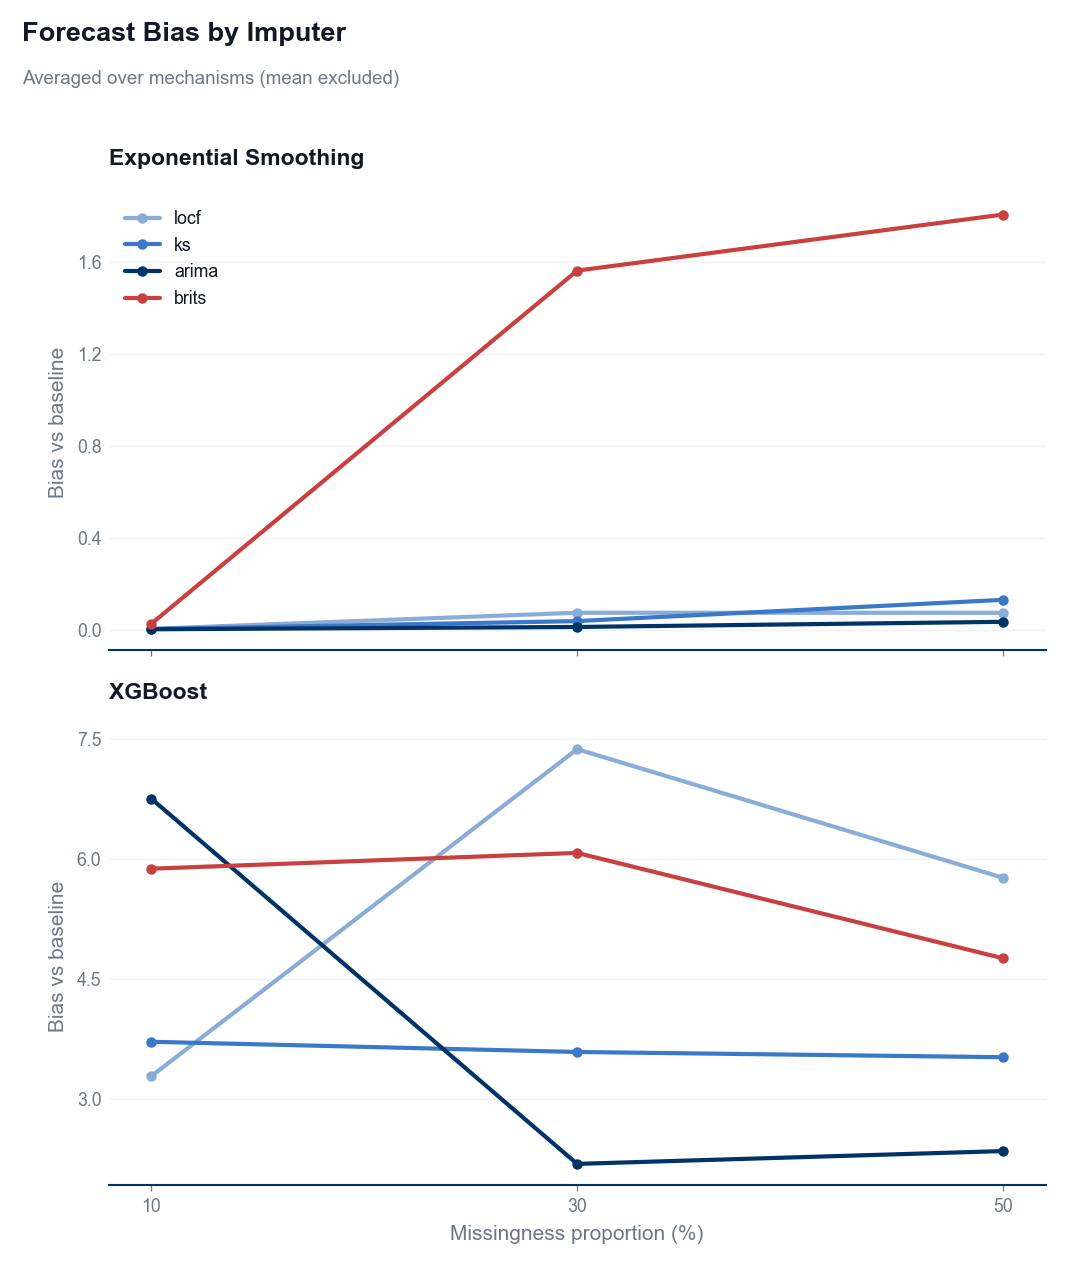

In [9]:
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
from src.figures_cfg import (apply_theme, IMPUTER_COLORS, PRIMARY, MUTED, INK, LIGHT, WHITE)
apply_theme()

forecasters = ["exp_smoothing", "xgboost"]
titles = {"exp_smoothing": "Exponential Smoothing", "xgboost": "XGBoost"}
imputers = ["locf", "ks", "arima", "brits"]        # mean excluded

agg = (bv_df[bv_df["imputer"] != "mean"]
       .groupby(["forecaster", "proportion", "imputer"])["bias_vs_baseline"]
       .mean().reset_index())

fig, axes = plt.subplots(2, 1, figsize=(7, 8), sharex=True)   # portrait + shared x
for ax, fc in zip(axes, forecasters):
    sub = agg[agg["forecaster"] == fc]
    for imp in imputers:
        g = sub[sub["imputer"] == imp].sort_values("proportion")
        ax.plot(g["proportion"], g["bias_vs_baseline"], marker="o", markersize=4,
                color=IMPUTER_COLORS[imp], label=imp)
    ax.spines["top"].set_visible(False); ax.spines["right"].set_visible(False)
    ax.spines["left"].set_visible(False)
    ax.spines["bottom"].set_color(PRIMARY); ax.spines["bottom"].set_linewidth(1.0)
    ax.grid(axis="y", color=LIGHT, linewidth=0.7); ax.set_facecolor(WHITE)
    ax.tick_params(axis="y", labelsize=8.5, colors=MUTED)
    ax.yaxis.set_major_locator(ticker.MaxNLocator(nbins=5, prune="both"))
    ax.set_ylabel("Bias vs baseline", color=MUTED, fontsize=10)   # both panels
    ax.set_title(titles[fc], color=INK, fontweight="bold", fontsize=11, loc="left", pad=14)

axes[-1].set_xticks([10, 30, 50])                                # bottom panel only
axes[-1].tick_params(axis="x", labelsize=8.5, colors=MUTED)
axes[-1].set_xlabel("Missingness proportion (%)", color=MUTED, fontsize=10)
axes[0].legend(frameon=False, fontsize=8.5, labelcolor=INK, loc="upper left")

axes[0].set_ylabel("Bias vs baseline", color=MUTED, fontsize=10)
axes[0].legend(frameon=False, fontsize=8.5, labelcolor=INK, loc="upper left")
fig.suptitle("Forecast Bias by Imputer", x=0.0, ha="left",
             fontsize=13, fontweight="bold", color=INK, y=1.04)
fig.text(0.0, 1.00, "Averaged over mechanisms (mean excluded)",
         ha="left", fontsize=9, color=MUTED, va="top")
fig.tight_layout()
fig.savefig(OUTPUTS / "figures/forecasting/bias_by_imputer_forecaster.png")
plt.show()

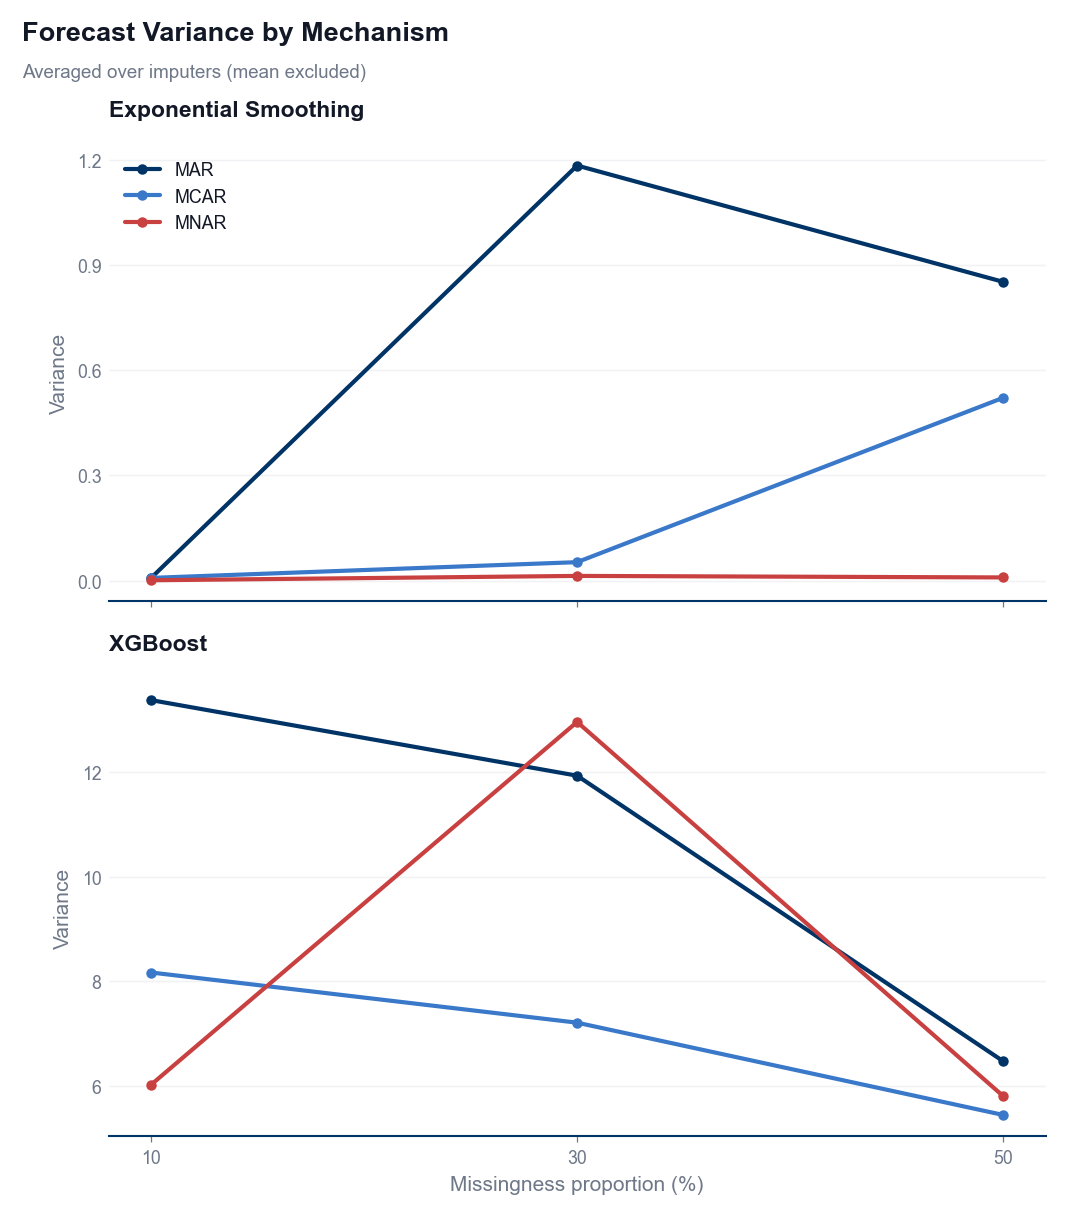

In [10]:
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
from src.figures_cfg import (apply_theme, PRIMARY, MUTED, INK, LIGHT, WHITE, MECHANISM_ORDER, MECHANISM_COLORS)
apply_theme()

forecasters = ["exp_smoothing", "xgboost"]
titles = {"exp_smoothing": "Exponential Smoothing", "xgboost": "XGBoost"}

agg = (bv_df[bv_df["imputer"] != "mean"]
       .groupby(["forecaster", "proportion", "mechanism"])["variance"]
       .mean().reset_index())

fig, axes = plt.subplots(2, 1, figsize=(7, 8), sharex=True)
for ax, fc in zip(axes, forecasters):
    sub = agg[agg["forecaster"] == fc]
    for mech in MECHANISM_ORDER:
        g = sub[sub["mechanism"] == mech].sort_values("proportion")
        ax.plot(g["proportion"], g["variance"], marker="o", markersize=4,
                color=MECHANISM_COLORS[mech], label=mech.upper())
    ax.spines["top"].set_visible(False); ax.spines["right"].set_visible(False)
    ax.spines["left"].set_visible(False)
    ax.spines["bottom"].set_color(PRIMARY); ax.spines["bottom"].set_linewidth(1.0)
    ax.grid(axis="y", color=LIGHT, linewidth=0.7); ax.set_facecolor(WHITE)
    ax.tick_params(axis="y", labelsize=8.5, colors=MUTED)
    ax.yaxis.set_major_locator(ticker.MaxNLocator(nbins=5, prune="both"))
    ax.set_ylabel("Variance", color=MUTED, fontsize=10)
    ax.set_title(titles[fc], color=INK, fontweight="bold", fontsize=11, loc="left", pad=14)

axes[-1].set_xticks([10, 30, 50])
axes[-1].tick_params(axis="x", labelsize=8.5, colors=MUTED)
axes[-1].set_xlabel("Missingness proportion (%)", color=MUTED, fontsize=10)
axes[0].legend(frameon=False, fontsize=8.5, labelcolor=INK, loc="upper left")

fig.suptitle("Forecast Variance by Mechanism", x=0.0, ha="left",
             fontsize=13, fontweight="bold", color=INK, y=1.0)
fig.text(0.0, 0.965, "Averaged over imputers (mean excluded)",
         ha="left", fontsize=9, color=MUTED, va="top")
fig.tight_layout()
fig.savefig(OUTPUTS / "figures/forecasting/variance_by_mechanism.png")
plt.show()

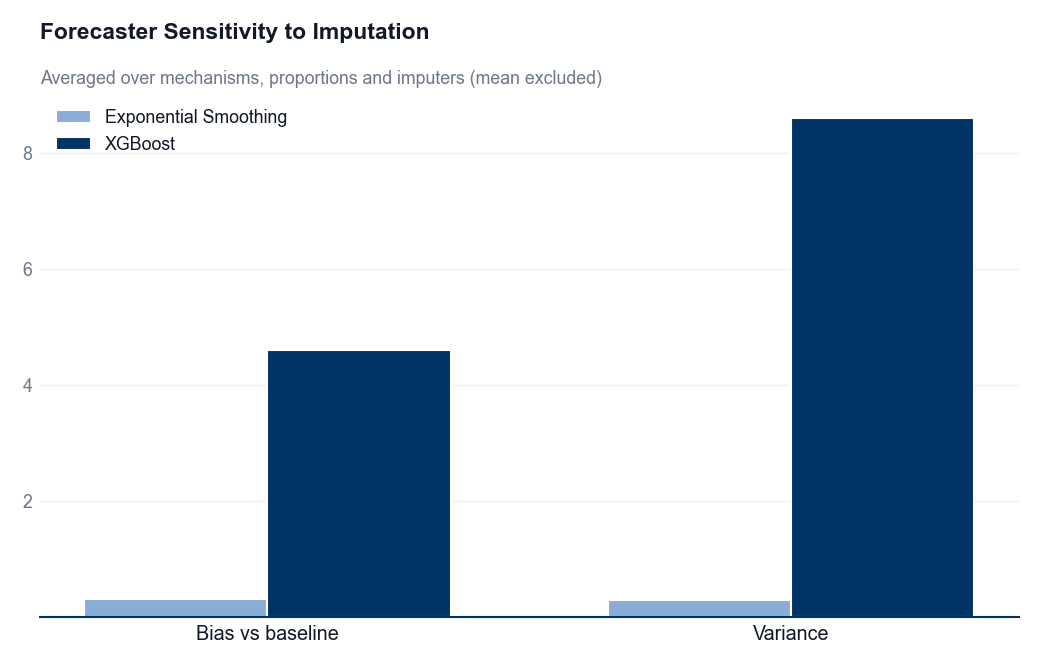

In [11]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
from src.figures_cfg import (apply_theme, PRIMARY, MUTED, INK, LIGHT, WHITE)
apply_theme()

sub = bv_df[bv_df["imputer"] != "mean"]
agg = sub.groupby("forecaster")[["bias_vs_baseline", "variance"]].mean()
agg = agg.reindex(["exp_smoothing", "xgboost"])

metrics = ["bias_vs_baseline", "variance"]
labels  = ["Bias vs baseline", "Variance"]
fc_names = {"exp_smoothing": "Exponential Smoothing", "xgboost": "XGBoost"}
fc_colors = {"exp_smoothing": "#8AADD8", "xgboost": PRIMARY}

x = np.arange(len(metrics))
w = 0.35

fig, ax = plt.subplots(figsize=(7, 4.5))
for i, fc in enumerate(agg.index):
    ax.bar(x + (i - 0.5) * w, agg.loc[fc, metrics].values, w,
           color=fc_colors[fc], label=fc_names[fc])

ax.spines["top"].set_visible(False); ax.spines["right"].set_visible(False)
ax.spines["left"].set_visible(False)
ax.spines["bottom"].set_color(PRIMARY); ax.spines["bottom"].set_linewidth(1.0)
ax.grid(axis="y", color=LIGHT, linewidth=0.7); ax.set_facecolor(WHITE)
ax.set_xticks(x); ax.set_xticklabels(labels, fontsize=9.5, color=INK)
ax.tick_params(axis="x", length=0)
ax.tick_params(axis="y", labelsize=8.5, colors=MUTED)
ax.yaxis.set_major_locator(ticker.MaxNLocator(nbins=5, prune="both"))
ax.set_title("Forecaster Sensitivity to Imputation",
             color=INK, fontweight="bold", fontsize=11, loc="left", pad=26)
ax.text(0, 1.01, "Averaged over mechanisms, proportions and imputers (mean excluded)",
        transform=ax.transAxes, color=MUTED, fontsize=8.5, va="bottom")
ax.legend(frameon=False, fontsize=8.5, labelcolor=INK, loc="upper left")

fig.tight_layout()
fig.savefig(OUTPUTS / "figures/forecasting/forecaster_sensitivity.png")
plt.show()

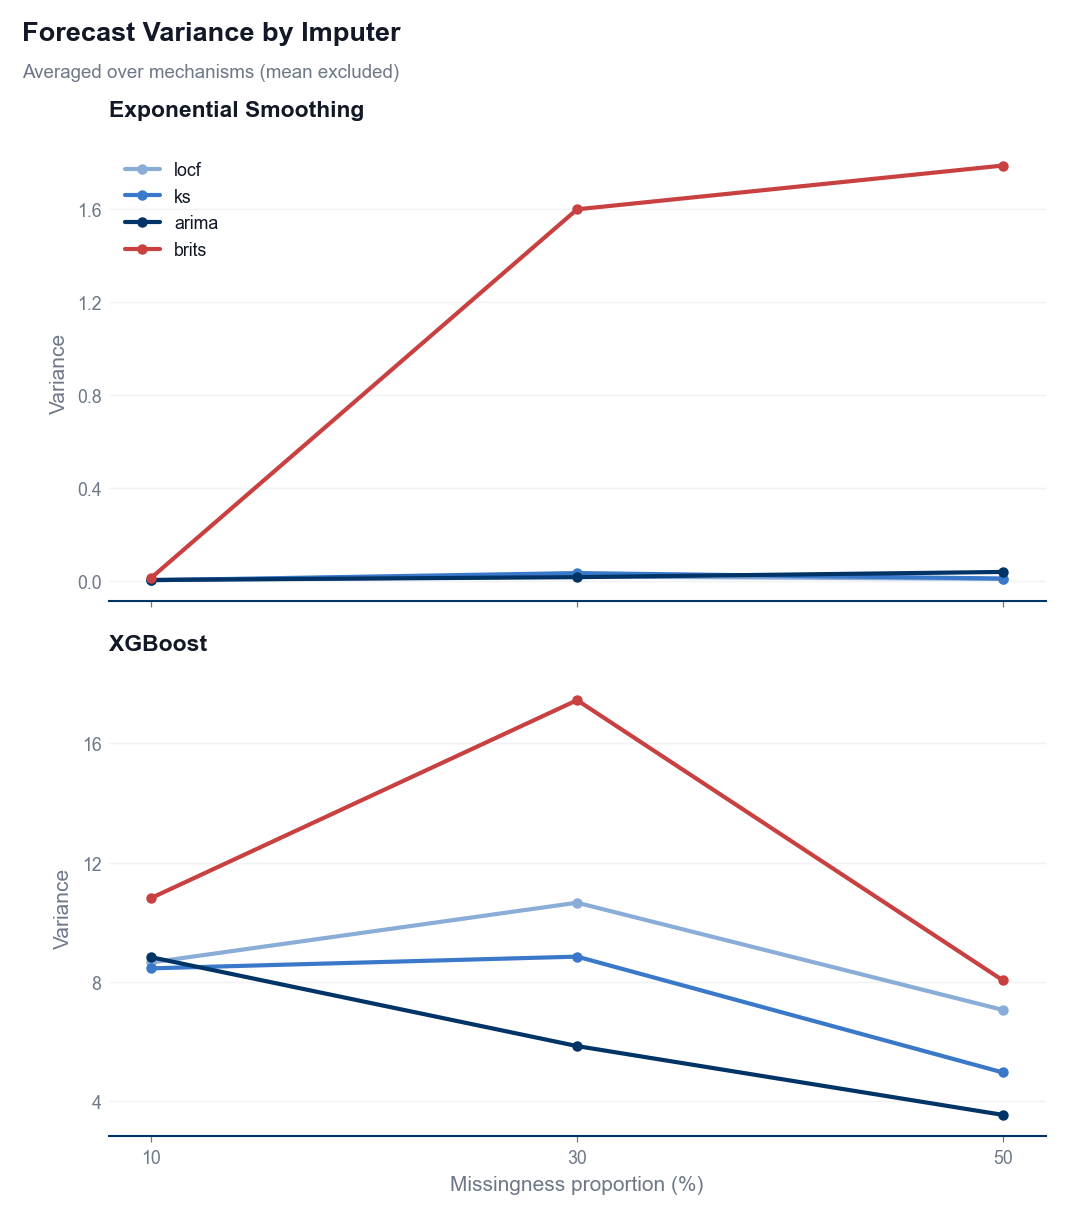

In [12]:
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
from src.figures_cfg import (apply_theme, IMPUTER_COLORS, PRIMARY, MUTED, INK, LIGHT, WHITE)
apply_theme()

forecasters = ["exp_smoothing", "xgboost"]
titles = {"exp_smoothing": "Exponential Smoothing", "xgboost": "XGBoost"}
imputers = ["locf", "ks", "arima", "brits"]

agg = (bv_df[bv_df["imputer"] != "mean"]
       .groupby(["forecaster", "proportion", "imputer"])["variance"]
       .mean().reset_index())

fig, axes = plt.subplots(2, 1, figsize=(7, 8), sharex=True)
for ax, fc in zip(axes, forecasters):
    sub = agg[agg["forecaster"] == fc]
    for imp in imputers:
        g = sub[sub["imputer"] == imp].sort_values("proportion")
        ax.plot(g["proportion"], g["variance"], marker="o", markersize=4,
                color=IMPUTER_COLORS[imp], label=imp)
    ax.spines["top"].set_visible(False); ax.spines["right"].set_visible(False)
    ax.spines["left"].set_visible(False)
    ax.spines["bottom"].set_color(PRIMARY); ax.spines["bottom"].set_linewidth(1.0)
    ax.grid(axis="y", color=LIGHT, linewidth=0.7); ax.set_facecolor(WHITE)
    ax.tick_params(axis="y", labelsize=8.5, colors=MUTED)
    ax.yaxis.set_major_locator(ticker.MaxNLocator(nbins=5, prune="both"))
    ax.set_ylabel("Variance", color=MUTED, fontsize=10)
    ax.set_title(titles[fc], color=INK, fontweight="bold", fontsize=11, loc="left", pad=14)

axes[-1].set_xticks([10, 30, 50])
axes[-1].tick_params(axis="x", labelsize=8.5, colors=MUTED)
axes[-1].set_xlabel("Missingness proportion (%)", color=MUTED, fontsize=10)
axes[0].legend(frameon=False, fontsize=8.5, labelcolor=INK, loc="upper left")

fig.suptitle("Forecast Variance by Imputer", x=0.0, ha="left",
             fontsize=13, fontweight="bold", color=INK, y=1.0)
fig.text(0.0, 0.965, "Averaged over mechanisms (mean excluded)",
         ha="left", fontsize=9, color=MUTED, va="top")
fig.tight_layout()
fig.savefig(OUTPUTS / "figures/forecasting/forecaster_variance_by_imputer.png")
plt.show()